**Cell 00 · Cell index** — each cell is prefixed with `Cell NN · name` (also in cell metadata `cell_label`).

- **01 · Intro**
- **02 · Load & clean**
- **03 · Unified summary overview**
- **04 · Unified summary code**
- **05 · Summary plots overview**
- **06 · Summary plots code**
- **07 · Modeling target overview**
- **08 · Modeling target code**
- **09 · Scale predictors overview**
- **10 · Scale & modeling table code**
- **11 · BMI skew — transform & scale**
- **12 · Boruta overview**
- **13 · Boruta RF table**
- **14 · Boruta plot**
- **15 · Binary modeling overview**
- **16 · Logistic regression (fit & evaluation)**
- **17 · Random forest (fit & evaluation)**
- **18 · Model comparison**
- **19 · Boruta-confirmed logistic overview**
- **20 · Logistic — Boruta confirmed**
- **21 · Three-model comparison**


**Cell 01 · Intro**

# Diabetes Prediction Model

Pipeline for **BRFSS 2015** health indicators ([UCI / Kaggle diabetes health indicators](https://archive.ics.uci.edu/dataset/891/cdc+diabetes+health+indicators)): load and clean **`diabetes_binary_health_indicators_BRFSS2015.csv`**, unified descriptive summary, exploratory plots, binary modeling target **`diabetes_outcome`**, and a standardized modeling matrix **`df_model_scaled`**.

Each row is one survey respondent. **Target:** diabetes (`Diabetes_binary` → **`diabetes_outcome`**, 0/1). Predictors are the other BRFSS health, behavior, and demographic fields (including **`heart_disease_or_attack`**).

**Uneven classes:** About **14%** of this file has diabetes and **86%** does not. A model that always says “no diabetes” would still be **86% accurate**, so we do not rely on accuracy alone.

**What goes into the fit:** Each cross-validation fold passes **`class_weight`** into logistic regression and the random forest: two numbers that say how costly a wrong answer is for each label. Rows with **diabetes** get a weight about **6×** higher than rows without (because they are ~6× less common). That is **`dm_class_weight_dict`** in Cell 16—we do **not** copy or drop rows to balance the table. Optional **`DM_MINORITY_CLASS_WEIGHT_EMPHASIS`** in Cell 16 multiplies the diabetes weight if you want an even stronger penalty for missing diabetes cases.

**Feature screening:** Cells **12–14** run an exploratory **Boruta-style** random forest (rankings only; all predictors stay in the model).

**Evaluation:** **4-fold cross-validation** plus metrics described in Cell 15. For the same steps on a **50/50** sample, see **`Diabetes Prediction Model (5050 Split).ipynb`**.


In [44]:
# Cell 02 · Load & clean
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt


def dm_format_plain_axes(ax: plt.Axes) -> None:
    for axis in ("x", "y"):
        try:
            ax.ticklabel_format(style="plain", axis=axis, useOffset=False)
        except AttributeError:
            pass


def dm_format_confusion_matrix_ax(ax: plt.Axes) -> None:
    for text in ax.texts:
        raw = text.get_text().strip()
        if not raw:
            continue
        try:
            val = float(raw.replace(",", ""))
        except ValueError:
            continue
        if abs(val - round(val)) < 1e-9:
            iv = int(round(val))
            text.set_text(f"{iv:,}" if abs(iv) >= 1000 else str(iv))
        else:
            text.set_text(f"{val:.4f}")


def dm_format_figure(fig: plt.Figure) -> None:
    for ax in fig.get_axes():
        dm_format_plain_axes(ax)
        if len(ax.texts) == 4:
            dm_format_confusion_matrix_ax(ax)


def _dm_pandas_float(x) -> str:
    try:
        if pd.isna(x):
            return ""
    except (TypeError, ValueError):
        pass
    try:
        return f"{float(x):.4f}"
    except (TypeError, ValueError):
        return str(x)


def dm_configure_display() -> None:
    pd.set_option("display.float_format", _dm_pandas_float)
    pd.set_option("display.precision", 4)
    plt.rcParams["axes.formatter.useoffset"] = False
    plt.rcParams["axes.formatter.limits"] = (-15, 15)

    _original_show = plt.show

    def _show_plain_axes(*args, **kwargs):
        for num in plt.get_fignums():
            dm_format_figure(plt.figure(num))
        _original_show(*args, **kwargs)

    plt.show = _show_plain_axes


dm_configure_display()


DATA_DIR = Path(".")
DATA_FILE = DATA_DIR / "diabetes_binary_health_indicators_BRFSS2015.csv"
COMPILED_DIR = DATA_DIR / "compiled"
COMPILED_DIR.mkdir(exist_ok=True)

COLUMN_RENAME = {
    "Diabetes_binary": "diabetes_binary",
    "HighBP": "high_bp",
    "HighChol": "high_chol",
    "CholCheck": "chol_check",
    "BMI": "bmi",
    "Smoker": "smoker",
    "Stroke": "stroke",
    "HeartDiseaseorAttack": "heart_disease_or_attack",
    "PhysActivity": "phys_activity",
    "Fruits": "fruits",
    "Veggies": "veggies",
    "HvyAlcoholConsump": "hvy_alcohol_consump",
    "AnyHealthcare": "any_healthcare",
    "NoDocbcCost": "no_docbc_cost",
    "GenHlth": "gen_hlth",
    "MentHlth": "ment_hlth",
    "PhysHlth": "phys_hlth",
    "DiffWalk": "diff_walk",
    "Sex": "sex",
    "Age": "age",
    "Education": "education",
    "Income": "income",
}

df_raw = pd.read_csv(DATA_FILE)
df_raw = df_raw.rename(columns=COLUMN_RENAME)

# BRFSS export: numeric 0/1 and coded ordinals; enforce numeric dtypes
for col in df_raw.columns:
    df_raw[col] = pd.to_numeric(df_raw[col], errors="coerce")

n_before = len(df_raw)
df_raw = df_raw.dropna(how="any")
if len(df_raw) < n_before:
    print(f"Dropped {n_before - len(df_raw):,} rows with missing values")

dup = int(df_raw.duplicated().sum())
if dup:
    print(f"Duplicate rows: {dup:,} (kept for BRFSS survey-weight fidelity)")

print(f"Loaded: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")
print(f"Diabetes prevalence: {df_raw['diabetes_binary'].mean():.3%}")

# Working frame for summaries (predictors + outcome; no extra encoding required)
df = df_raw.copy()
df.head()


Duplicate rows: 24,206 (kept for BRFSS survey-weight fidelity)
Loaded: 253,680 rows × 22 columns
Diabetes prevalence: 13.933%


,diabetes_binary,high_bp,high_chol,chol_check,bmi,smoker,stroke,heart_disease_or_attack,phys_activity,fruits,...,any_healthcare,no_docbc_cost,gen_hlth,ment_hlth,phys_hlth,diff_walk,sex,age,education,income
0,0.0000,1.0000,1.0000,1.0000,40.0000,1.0000,0.0000,0.0000,0.0000,0.0000,...,1.0000,0.0000,5.0000,18.0000,15.0000,1.0000,0.0000,9.0000,4.0000,3.0000
1,0.0000,0.0000,0.0000,0.0000,25.0000,1.0000,0.0000,0.0000,1.0000,0.0000,...,0.0000,1.0000,3.0000,0.0000,0.0000,0.0000,0.0000,7.0000,6.0000,1.0000
2,0.0000,1.0000,1.0000,1.0000,28.0000,0.0000,0.0000,0.0000,0.0000,1.0000,...,1.0000,1.0000,5.0000,30.0000,30.0000,1.0000,0.0000,9.0000,4.0000,8.0000
3,0.0000,1.0000,0.0000,1.0000,27.0000,0.0000,0.0000,0.0000,1.0000,1.0000,...,1.0000,0.0000,2.0000,0.0000,0.0000,0.0000,0.0000,11.0000,3.0000,6.0000
4,0.0000,1.0000,1.0000,1.0000,24.0000,0.0000,0.0000,0.0000,1.0000,1.0000,...,1.0000,0.0000,2.0000,3.0000,0.0000,0.0000,0.0000,11.0000,5.0000,4.0000


**Cell 03 · Unified summary overview**

## Unified summary table

One row per column: data type, **measurement level** (BRFSS coding), counts, central tendency, spread, skew, and IQR outliers for **ratio** / **interval** fields only.


In [45]:
# Cell 04 · Unified summary code
measurement_levels = {
    "diabetes_binary": "nominal (binary)",
    "high_bp": "nominal (binary)",
    "high_chol": "nominal (binary)",
    "chol_check": "nominal (binary)",
    "bmi": "ratio",
    "smoker": "nominal (binary)",
    "stroke": "nominal (binary)",
    "heart_disease_or_attack": "nominal (binary)",
    "phys_activity": "nominal (binary)",
    "fruits": "nominal (binary)",
    "veggies": "nominal (binary)",
    "hvy_alcohol_consump": "nominal (binary)",
    "any_healthcare": "nominal (binary)",
    "no_docbc_cost": "nominal (binary)",
    "gen_hlth": "ordinal",
    "ment_hlth": "ordinal",
    "phys_hlth": "ordinal",
    "diff_walk": "nominal (binary)",
    "sex": "nominal (binary)",
    "age": "ordinal",
    "education": "ordinal",
    "income": "ordinal",
}


def column_mode(series: pd.Series):
    modes = series.mode(dropna=True)
    return modes.iloc[0] if len(modes) else np.nan


def iqr_outlier_count(series: pd.Series) -> int:
    values = pd.to_numeric(series, errors="coerce").dropna()
    if len(values) < 4:
        return 0
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return int(((values < lower) | (values > upper)).sum())


rows = []
for col in df.columns:
    s = df[col]
    is_numeric = pd.api.types.is_numeric_dtype(s)
    level = measurement_levels.get(col, "nominal")
    distribution_stats = level in {"interval", "ratio"}

    rows.append(
        {
            "column": col,
            "data_type": str(s.dtype),
            "measurement_level": level,
            "count": int(s.count()),
            "missing": int(s.isna().sum()),
            "unique_values": int(s.nunique()),
            "mean": float(s.mean()) if is_numeric else np.nan,
            "median": float(s.median()) if is_numeric else np.nan,
            "mode": column_mode(s),
            "min": float(s.min()) if is_numeric else np.nan,
            "max": float(s.max()) if is_numeric else np.nan,
            "range": float(s.max() - s.min()) if is_numeric else np.nan,
            "skew": float(stats.skew(s.dropna(), bias=False))
            if distribution_stats and s.notna().sum() >= 3
            else np.nan,
            "iqr_outlier_count": iqr_outlier_count(s)
            if distribution_stats
            else np.nan,
        }
    )

unified_summary = pd.DataFrame(rows).set_index("column")
for c in ["mean", "median", "min", "max", "range", "skew"]:
    unified_summary[c] = unified_summary[c].round(3)
unified_summary["iqr_outlier_count"] = unified_summary["iqr_outlier_count"].astype("Int64")
unified_summary


,data_type,measurement_level,count,missing,unique_values,mean,median,mode,min,max,range,skew,iqr_outlier_count
column,,,,,,,,,,,,,
diabetes_binary,float64,nominal (binary),253680,0,2,0.1390,0.0000,0.0000,0.0000,1.0000,1.0000,NaN,<NA>
high_bp,float64,nominal (binary),253680,0,2,0.4290,0.0000,0.0000,0.0000,1.0000,1.0000,NaN,<NA>
high_chol,float64,nominal (binary),253680,0,2,0.4240,0.0000,0.0000,0.0000,1.0000,1.0000,NaN,<NA>
chol_check,float64,nominal (binary),253680,0,2,0.9630,1.0000,1.0000,0.0000,1.0000,1.0000,NaN,<NA>
bmi,float64,ratio,253680,0,84,28.3820,27.0000,27.0000,12.0000,98.0000,86.0000,2.1220,9847
smoker,float64,nominal (binary),253680,0,2,0.4430,0.0000,0.0000,0.0000,1.0000,1.0000,NaN,<NA>
stroke,float64,nominal (binary),253680,0,2,0.0410,0.0000,0.0000,0.0000,1.0000,1.0000,NaN,<NA>
heart_disease_or_attack,float64,nominal (binary),253680,0,2,0.0940,0.0000,0.0000,0.0000,1.0000,1.0000,NaN,<NA>
phys_activity,float64,nominal (binary),253680,0,2,0.7570,1.0000,1.0000,0.0000,1.0000,1.0000,NaN,<NA>


**Cell 05 · Summary plots overview**

Key BRFSS distributions: **diabetes** outcome, **age** bracket by **sex**, **BMI by diabetes status**, and overall **raw BMI**.


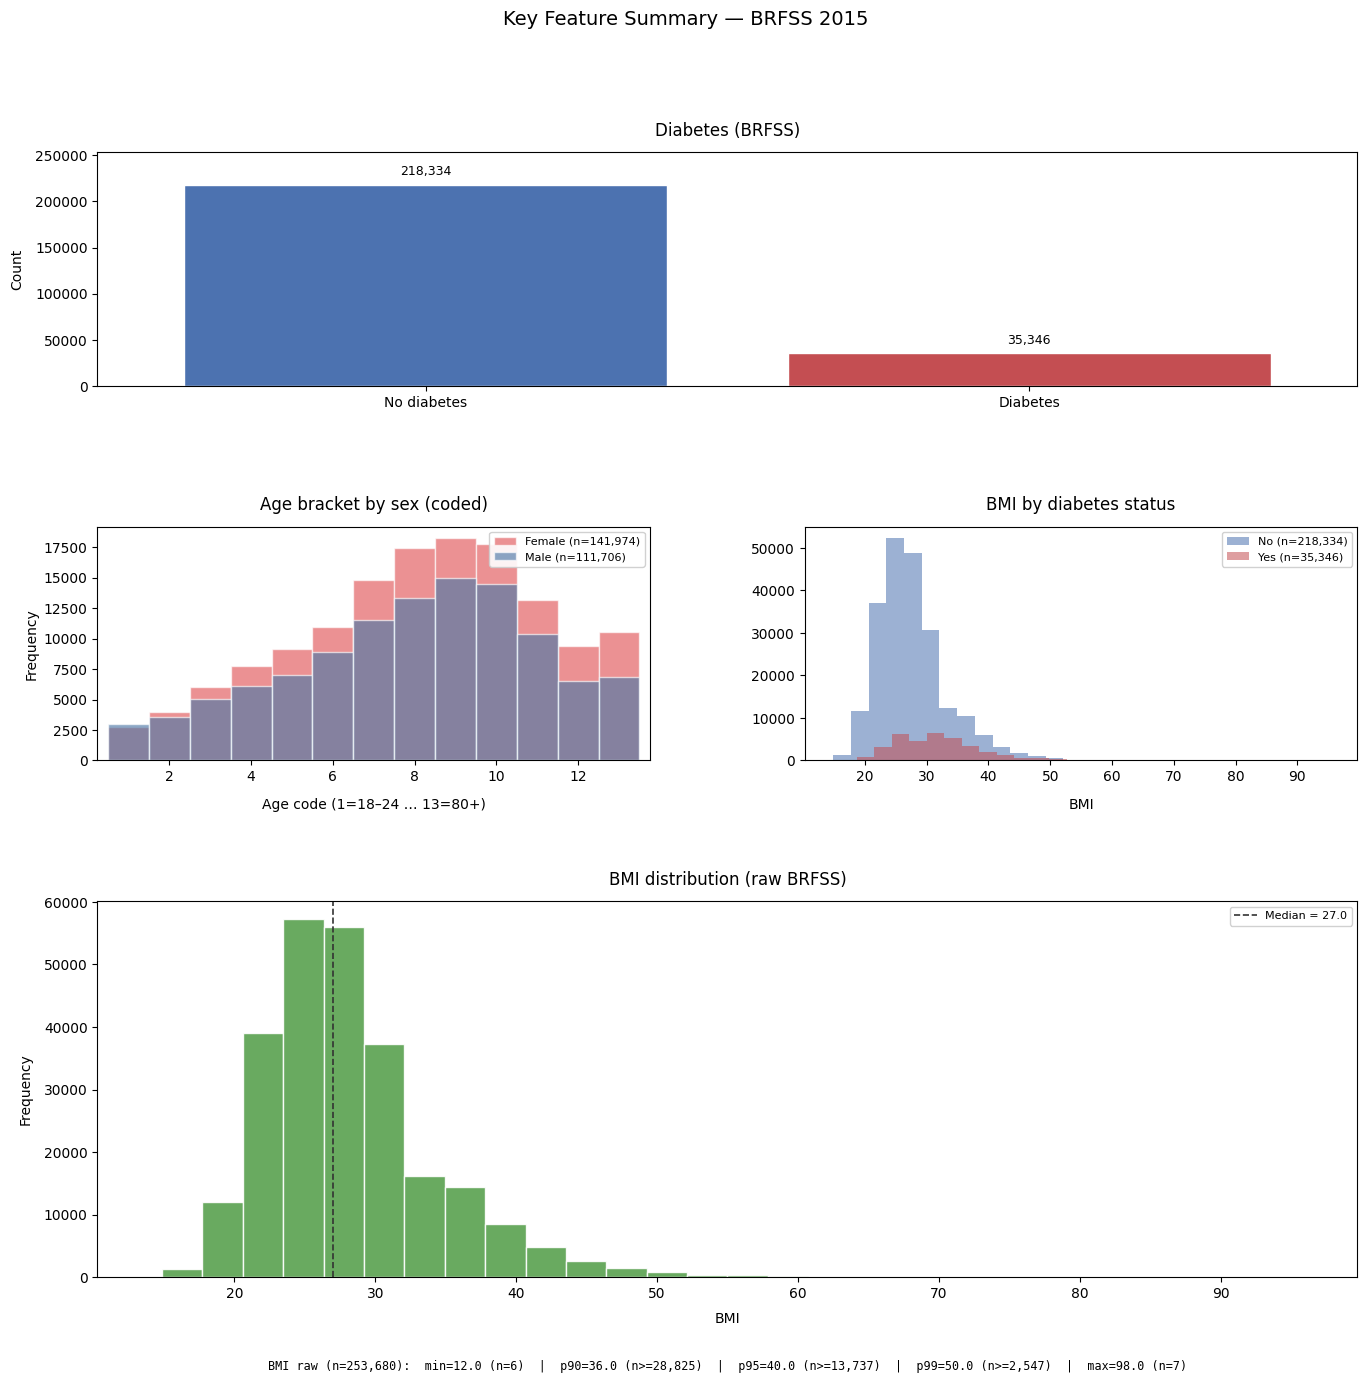

BMI raw (n=253,680):  min=12.0 (n=6)  |  p90=36.0 (n>=28,825)  |  p95=40.0 (n>=13,737)  |  p99=50.0 (n>=2,547)  |  max=98.0 (n=7)


In [46]:
# Cell 06 · Summary plots code
import matplotlib.pyplot as plt

AGE_LABELS = {
    1: "18–24",
    2: "25–29",
    3: "30–34",
    4: "35–39",
    5: "40–44",
    6: "45–49",
    7: "50–54",
    8: "55–59",
    9: "60–64",
    10: "65–69",
    11: "70–74",
    12: "75–79",
    13: "80+",
}
def dm_bmi_distribution_footer(series) -> str:
    s = series.dropna().astype(float)
    n_total = len(s)
    bmin = float(s.min())
    bmax = float(s.max())
    p90 = float(s.quantile(0.90))
    p95 = float(s.quantile(0.95))
    p99 = float(s.quantile(0.99))
    n_min = int((s == bmin).sum())
    n_max = int((s == bmax).sum())
    n_ge_p90 = int((s >= p90).sum())
    n_ge_p95 = int((s >= p95).sum())
    n_ge_p99 = int((s >= p99).sum())
    return (
        f"BMI raw (n={n_total:,}):  "
        f"min={bmin:.1f} (n={n_min:,})  |  "
        f"p90={p90:.1f} (n>={n_ge_p90:,})  |  "
        f"p95={p95:.1f} (n>={n_ge_p95:,})  |  "
        f"p99={p99:.1f} (n>={n_ge_p99:,})  |  "
        f"max={bmax:.1f} (n={n_max:,})"
    )


def dm_bar_count_labels(ax, bars, padding: float = 5) -> None:
    heights = [bar.get_height() for bar in bars]
    if not heights:
        return
    ax.bar_label(
        bars,
        labels=[f"{int(h):,}" for h in heights],
        padding=padding,
        fontsize=9,
    )
    ax.set_ylim(0, max(heights) * 1.16)


fig = plt.figure(figsize=(14, 15.0))
grid = fig.add_gridspec(3, 2, height_ratios=[0.92, 0.92, 1.48], hspace=0.50, wspace=0.28)

ax_outcome = fig.add_subplot(grid[0, :])
outcome_counts = df_raw["diabetes_binary"].value_counts().sort_index()
bars = ax_outcome.bar(
    ["No diabetes", "Diabetes"],
    [outcome_counts.get(0, 0), outcome_counts.get(1, 0)],
    color=["#4C72B0", "#C44E52"],
    edgecolor="white",
)
ax_outcome.set_title("Diabetes (BRFSS)", pad=12)
ax_outcome.set_ylabel("Count", labelpad=8)
ax_outcome.margins(x=0.08)
dm_bar_count_labels(ax_outcome, bars)

sex_colors = {0: "#E15759", 1: "#4E79A7"}
sex_labels = {0: "Female", 1: "Male"}

ax_age = fig.add_subplot(grid[1, 0])
for sex_code, label in sex_labels.items():
    ages = df_raw.loc[df_raw["sex"] == sex_code, "age"].dropna()
    ax_age.hist(
        ages,
        bins=np.arange(0.5, 14.5, 1),
        alpha=0.65,
        label=f"{label} (n={len(ages):,})",
        color=sex_colors[sex_code],
        edgecolor="white",
    )
ax_age.set_title("Age bracket by sex (coded)", pad=12)
ax_age.set_xlabel("Age code (1=18–24 … 13=80+)", labelpad=10)
ax_age.set_ylabel("Frequency")
ax_age.legend(fontsize=8, loc="upper right", framealpha=0.9)
ax_age.margins(x=0.02)

ax_bmi = fig.add_subplot(grid[1, 1])
for outcome, name, color in (
    (0, "No", "#4C72B0"),
    (1, "Yes", "#C44E52"),
):
    subset = df_raw.loc[df_raw["diabetes_binary"] == outcome, "bmi"]
    ax_bmi.hist(subset, bins=30, alpha=0.55, label=f"{name} (n={len(subset):,})", color=color)
ax_bmi.set_title("BMI by diabetes status", pad=12)
ax_bmi.set_xlabel("BMI", labelpad=10)
ax_bmi.legend(loc="upper right", fontsize=8, framealpha=0.9)
ax_bmi.margins(x=0.02)

ax_bmi_all = fig.add_subplot(grid[2, :])
bmi_vals = df_raw["bmi"].dropna()
ax_bmi_all.hist(
    bmi_vals,
    bins=30,
    color="#59A14F",
    edgecolor="white",
    alpha=0.9,
)
median_bmi = float(bmi_vals.median())
ax_bmi_all.axvline(
    median_bmi,
    color="#333333",
    linestyle="--",
    linewidth=1.2,
    label=f"Median = {median_bmi:.1f}",
)
ax_bmi_all.set_title("BMI distribution (raw BRFSS)", pad=12)
ax_bmi_all.set_xlabel("BMI", labelpad=8)
ax_bmi_all.set_ylabel("Frequency", labelpad=8)
ax_bmi_all.tick_params(axis="x", pad=3)
ax_bmi_all.margins(x=0.02)
ax_bmi_all.legend(loc="upper right", fontsize=8, framealpha=0.9)

fig.suptitle("Key Feature Summary — BRFSS 2015", fontsize=14, y=0.995)
fig.subplots_adjust(top=0.90, hspace=0.78, wspace=0.30, bottom=0.15, left=0.08, right=0.98)

bmi_footer = dm_bmi_distribution_footer(bmi_vals)
ax_bmi_all.text(
    0.5,
    -0.22,
    bmi_footer,
    transform=ax_bmi_all.transAxes,
    ha="center",
    va="top",
    fontsize=8.5,
    family="monospace",
    clip_on=False,
)
plt.show()
print(bmi_footer)


**Cell 07 · Modeling target overview**

## Modeling target (binary)

**`diabetes_outcome`** is the binary label for modeling (0 = no diabetes, 1 = diabetes). The source column **`diabetes_binary`** is dropped from predictors to avoid leakage; **`heart_disease_or_attack`** and other BRFSS fields remain as features.


In [47]:
# Cell 08 · Modeling target code
from IPython.display import display

DIABETES_OUTCOME_COL = "diabetes_outcome"

predictor_cols = [c for c in df.columns if c != "diabetes_binary"]
df_model = df[predictor_cols].copy()
df_model[DIABETES_OUTCOME_COL] = df_raw["diabetes_binary"].astype(int)

outcome_reference = pd.DataFrame(
    {
        "class_id": [0, 1],
        "label": ["No diabetes", "Diabetes"],
    }
)

print(f"Modeling table: {df_model.shape[0]:,} rows × {df_model.shape[1]} columns")
print(f"Outcome column: {DIABETES_OUTCOME_COL}")
display(outcome_reference)
print("\nClass counts:")
print(df_model[DIABETES_OUTCOME_COL].value_counts().sort_index().to_string())
df_model.head()


Modeling table: 253,680 rows × 22 columns
Outcome column: diabetes_outcome


,class_id,label
0,0,No diabetes
1,1,Diabetes



Class counts:
diabetes_outcome
0    218334
1     35346


,high_bp,high_chol,chol_check,bmi,smoker,stroke,heart_disease_or_attack,phys_activity,fruits,veggies,...,no_docbc_cost,gen_hlth,ment_hlth,phys_hlth,diff_walk,sex,age,education,income,diabetes_outcome
0,1.0000,1.0000,1.0000,40.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,...,0.0000,5.0000,18.0000,15.0000,1.0000,0.0000,9.0000,4.0000,3.0000,0
1,0.0000,0.0000,0.0000,25.0000,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000,...,1.0000,3.0000,0.0000,0.0000,0.0000,0.0000,7.0000,6.0000,1.0000,0
2,1.0000,1.0000,1.0000,28.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,...,1.0000,5.0000,30.0000,30.0000,1.0000,0.0000,9.0000,4.0000,8.0000,0
3,1.0000,0.0000,1.0000,27.0000,0.0000,0.0000,0.0000,1.0000,1.0000,1.0000,...,0.0000,2.0000,0.0000,0.0000,0.0000,0.0000,11.0000,3.0000,6.0000,0
4,1.0000,1.0000,1.0000,24.0000,0.0000,0.0000,0.0000,1.0000,1.0000,1.0000,...,0.0000,2.0000,3.0000,0.0000,0.0000,0.0000,11.0000,5.0000,4.0000,0


**Cell 09 · Scale predictors overview**

### Transform and scale continuous predictors

**`bmi`** is right-skewed (typical skew > 1). **`StandardScaler` alone does not remove skew** — it only centers and rescales. For logistic regression we want a smoother, more symmetric predictor so the **log-odds are approximately linear in BMI** and extreme values carry less leverage.

Pipeline for ratio columns (currently **`bmi`** only): **`PowerTransformer`** (Yeo–Johnson) → **`StandardScaler`**. Ordinal BRFSS codes and binary indicators stay on their original scales. Output: **`df_model_scaled`** for downstream classifiers.


In [48]:
# Cell 10 · Scale & modeling table code
from IPython.display import display

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PowerTransformer, StandardScaler

if "df_model" not in globals():
    raise NameError("Run Cell 08 (modeling target) first.")
if "measurement_levels" not in globals():
    raise NameError("Run Cell 04 (unified summary) first.")

CONTINUOUS_LEVELS = {"ratio", "interval"}

MODELING_PREDICTOR_COLS = [c for c in df_model.columns if c != DIABETES_OUTCOME_COL]
df_model_modeling = df_model[MODELING_PREDICTOR_COLS + [DIABETES_OUTCOME_COL]].copy()

CONTINUOUS_PREDICTOR_COLS = [
    c
    for c in MODELING_PREDICTOR_COLS
    if measurement_levels.get(c) in CONTINUOUS_LEVELS
]
ORDINAL_OR_NOMINAL_COLS = [
    c for c in MODELING_PREDICTOR_COLS if c not in CONTINUOUS_PREDICTOR_COLS
]

df_model_scaled = df_model_modeling.copy()
dm_continuous_preprocessors: dict[str, Pipeline] = {}
for col in CONTINUOUS_PREDICTOR_COLS:
    pipe = Pipeline(
        [
            ("yeo_johnson", PowerTransformer(method="yeo-johnson", standardize=False)),
            ("standardize", StandardScaler()),
        ]
    )
    values = df_model_modeling[[col]].astype(float)
    df_model_scaled[col] = pipe.fit_transform(values).ravel()
    dm_continuous_preprocessors[col] = pipe

print(
    f"Modeling table: {df_model_modeling.shape[0]:,} rows × {df_model_modeling.shape[1]} columns "
    f"({len(MODELING_PREDICTOR_COLS)} predictors + {DIABETES_OUTCOME_COL})"
)
print(
    f"Continuous columns (Yeo–Johnson + StandardScaler) ({len(CONTINUOUS_PREDICTOR_COLS)}): "
    f"{CONTINUOUS_PREDICTOR_COLS}"
)
print(f"Unscaled predictors ({len(ORDINAL_OR_NOMINAL_COLS)}): {ORDINAL_OR_NOMINAL_COLS}")


def _count_iqr_outliers(series: pd.Series) -> int:
    if "iqr_outlier_count" in globals():
        return int(iqr_outlier_count(series))
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return int(((series < lower) | (series > upper)).sum())


def _final_modeling_feature_summary(frame: pd.DataFrame, features: list[str]) -> pd.DataFrame:
    rows: list[dict] = []
    for col in features:
        s = pd.to_numeric(frame[col], errors="coerce")
        vals = s.dropna()
        level = measurement_levels.get(col, "unknown")
        distribution_stats = level in {"interval", "ratio"}
        rows.append(
            {
                "feature": col,
                "measurement_level": level,
                "transformed_scaled": col in CONTINUOUS_PREDICTOR_COLS,
                "count": int(vals.count()),
                "mean": round(float(vals.mean()), 4) if len(vals) else None,
                "std": round(float(vals.std(ddof=0)), 4) if len(vals) else None,
                "min": round(float(vals.min()), 4) if len(vals) else None,
                "max": round(float(vals.max()), 4) if len(vals) else None,
                "skew": round(float(vals.skew()), 3) if len(vals) >= 3 else None,
                "iqr_outliers": _count_iqr_outliers(vals)
                if distribution_stats and len(vals) >= 4
                else None,
            }
        )
    return pd.DataFrame(rows).set_index("feature")


print("\n=== Final modeling matrix — feature summary ===")
display(_final_modeling_feature_summary(df_model_scaled, MODELING_PREDICTOR_COLS))

print("\n=== Final modeling matrix — first rows ===")
display(df_model_scaled.head(10))

export_path = COMPILED_DIR / "brfss_diabetes_modeling_table.parquet"
try:
    df_model_scaled.to_parquet(export_path, index=False)
    print(f"\nSaved: {export_path}")
except Exception as exc:
    csv_path = COMPILED_DIR / "brfss_diabetes_modeling_table.csv"
    df_model_scaled.to_csv(csv_path, index=False)
    print(f"\nParquet unavailable ({exc}); saved CSV: {csv_path}")


Modeling table: 253,680 rows × 22 columns (21 predictors + diabetes_outcome)
Continuous columns (Yeo–Johnson + StandardScaler) (1): ['bmi']
Unscaled predictors (20): ['high_bp', 'high_chol', 'chol_check', 'smoker', 'stroke', 'heart_disease_or_attack', 'phys_activity', 'fruits', 'veggies', 'hvy_alcohol_consump', 'any_healthcare', 'no_docbc_cost', 'gen_hlth', 'ment_hlth', 'phys_hlth', 'diff_walk', 'sex', 'age', 'education', 'income']

=== Final modeling matrix — feature summary ===


,measurement_level,transformed_scaled,count,mean,std,min,max,skew,iqr_outliers
feature,,,,,,,,,
high_bp,nominal (binary),False,253680,0.4290,0.4949,0.0000,1.0000,0.2870,NaN
high_chol,nominal (binary),False,253680,0.4241,0.4942,0.0000,1.0000,0.3070,NaN
chol_check,nominal (binary),False,253680,0.9627,0.1896,0.0000,1.0000,-4.8810,NaN
bmi,ratio,True,253680,0.0000,1.0000,-5.8149,3.8907,-0.0250,3031.0000
smoker,nominal (binary),False,253680,0.4432,0.4968,0.0000,1.0000,0.2290,NaN
stroke,nominal (binary),False,253680,0.0406,0.1973,0.0000,1.0000,4.6570,NaN
heart_disease_or_attack,nominal (binary),False,253680,0.0942,0.2921,0.0000,1.0000,2.7790,NaN
phys_activity,nominal (binary),False,253680,0.7565,0.4292,0.0000,1.0000,-1.1960,NaN
fruits,nominal (binary),False,253680,0.6343,0.4816,0.0000,1.0000,-0.5570,NaN



=== Final modeling matrix — first rows ===


,high_bp,high_chol,chol_check,bmi,smoker,stroke,heart_disease_or_attack,phys_activity,fruits,veggies,...,no_docbc_cost,gen_hlth,ment_hlth,phys_hlth,diff_walk,sex,age,education,income,diabetes_outcome
0,1.0000,1.0000,1.0000,1.6386,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,...,0.0000,5.0000,18.0000,15.0000,1.0000,0.0000,9.0000,4.0000,3.0000,0
1,0.0000,0.0000,0.0000,-0.4457,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000,...,1.0000,3.0000,0.0000,0.0000,0.0000,0.0000,7.0000,6.0000,1.0000,0
2,1.0000,1.0000,1.0000,0.1345,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,...,1.0000,5.0000,30.0000,30.0000,1.0000,0.0000,9.0000,4.0000,8.0000,0
3,1.0000,0.0000,1.0000,-0.0457,0.0000,0.0000,0.0000,1.0000,1.0000,1.0000,...,0.0000,2.0000,0.0000,0.0000,0.0000,0.0000,11.0000,3.0000,6.0000,0
4,1.0000,1.0000,1.0000,-0.6684,0.0000,0.0000,0.0000,1.0000,1.0000,1.0000,...,0.0000,2.0000,3.0000,0.0000,0.0000,0.0000,11.0000,5.0000,4.0000,0
5,1.0000,1.0000,1.0000,-0.4457,1.0000,0.0000,0.0000,1.0000,1.0000,1.0000,...,0.0000,2.0000,0.0000,2.0000,0.0000,1.0000,10.0000,6.0000,8.0000,0
6,1.0000,0.0000,1.0000,0.4618,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,...,0.0000,3.0000,0.0000,14.0000,0.0000,0.0000,9.0000,6.0000,7.0000,0
7,1.0000,1.0000,1.0000,-0.4457,1.0000,0.0000,0.0000,1.0000,0.0000,1.0000,...,0.0000,3.0000,0.0000,0.0000,1.0000,0.0000,11.0000,4.0000,4.0000,0
8,1.0000,1.0000,1.0000,0.4618,1.0000,0.0000,1.0000,0.0000,1.0000,1.0000,...,0.0000,5.0000,30.0000,30.0000,1.0000,0.0000,9.0000,5.0000,1.0000,1
9,0.0000,0.0000,1.0000,-0.6684,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,...,0.0000,2.0000,0.0000,0.0000,0.0000,1.0000,8.0000,4.0000,3.0000,0



Saved: compiled\brfss_diabetes_modeling_table.parquet


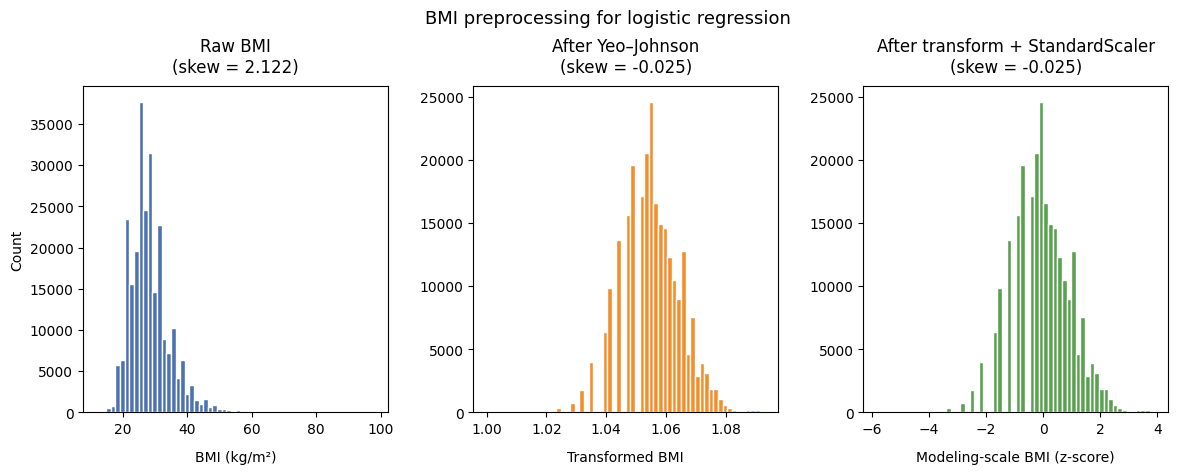

BMI skew: raw 2.1220 → Yeo–Johnson -0.0254 → modeling matrix -0.0254


In [49]:
# Cell 11 · BMI skew — Yeo–Johnson transform then StandardScaler
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.preprocessing import PowerTransformer

if "df_model_modeling" not in globals() or "df_model_scaled" not in globals():
    raise NameError("Run Cell 10 (scale & modeling table) first.")

bmi_raw = df_model_modeling["bmi"].astype(float)
bmi_yj = PowerTransformer(method="yeo-johnson", standardize=False).fit_transform(
    bmi_raw.values.reshape(-1, 1)
).ravel()
bmi_model = df_model_scaled["bmi"].astype(float)

skew_raw = float(stats.skew(bmi_raw, bias=False))
skew_yj = float(stats.skew(bmi_yj, bias=False))
skew_model = float(stats.skew(bmi_model, bias=False))

fig, axes = plt.subplots(1, 3, figsize=(14, 4.8))
axes[0].hist(bmi_raw, bins=60, color="#4C72B0", edgecolor="white")
axes[0].set_title(f"Raw BMI\n(skew = {skew_raw:.3f})", pad=10)
axes[0].set_xlabel("BMI (kg/m²)", labelpad=10)
axes[0].set_ylabel("Count")

axes[1].hist(bmi_yj, bins=60, color="#F28E2B", edgecolor="white")
axes[1].set_title(f"After Yeo–Johnson\n(skew = {skew_yj:.3f})", pad=10)
axes[1].set_xlabel("Transformed BMI", labelpad=10)

axes[2].hist(bmi_model, bins=60, color="#59A14F", edgecolor="white")
axes[2].set_title(f"After transform + StandardScaler\n(skew = {skew_model:.3f})", pad=10)
axes[2].set_xlabel("Modeling-scale BMI (z-score)", labelpad=10)

fig.suptitle("BMI preprocessing for logistic regression", fontsize=13, y=0.98)
fig.subplots_adjust(top=0.82, wspace=0.28, bottom=0.14)
plt.show()

print(
    f"BMI skew: raw {skew_raw:.4f} → Yeo–Johnson {skew_yj:.4f} → "
    f"modeling matrix {skew_model:.4f}"
)


**Cell 12 · Boruta overview**

## Boruta-style feature importance (exploratory)

Random forest on **`diabetes_outcome`** with **shadow** features (column-wise permutations). Each real feature is compared to the max shadow importance each iteration:

- **confirmed** — beat max shadow in ≥ 60% of iterations  
- **rejected** — beat max shadow in ≤ 30%  
- **tentative** — in between  

**No features are dropped** from **`df_model_scaled`** for modeling in later cells; this is for ranking and interpretation only. On the full BRFSS file we use a **stratified subsample** for runtime (`BORUTA_MAX_ROWS`).


In [50]:
# Cell 13 · Boruta RF — table & rankings
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

if "df_model_scaled" not in globals() or "MODELING_PREDICTOR_COLS" not in globals():
    raise NameError("Run Cell 10 first.")

BORUTA_TARGET = DIABETES_OUTCOME_COL
BORUTA_FULL_RUN = False
if BORUTA_FULL_RUN:
    BORUTA_N_ITER, BORUTA_N_ESTIMATORS = 50, 500
else:
    BORUTA_N_ITER, BORUTA_N_ESTIMATORS = 15, 200
BORUTA_N_JOBS = 1
BORUTA_RANDOM_STATE = 42 if "DM_MODEL_RANDOM_STATE" not in globals() else DM_MODEL_RANDOM_STATE
BORUTA_MAX_ROWS = 20000

X_full = df_model_scaled[MODELING_PREDICTOR_COLS].astype(float)
y_full = df_model_scaled[BORUTA_TARGET].astype(int)
if len(y_full) > BORUTA_MAX_ROWS:
    X_boruta, _, y_boruta, _ = train_test_split(
        X_full,
        y_full,
        train_size=BORUTA_MAX_ROWS,
        stratify=y_full,
        random_state=BORUTA_RANDOM_STATE,
    )
    print(
        f"Boruta subsample: {len(y_boruta):,} rows (stratified from {len(y_full):,})"
    )
else:
    X_boruta, y_boruta = X_full, y_full

feature_names = list(X_boruta.columns)
hits = pd.Series(0, index=feature_names, dtype=int)
importance_history: dict[str, list[float]] = {f: [] for f in feature_names}
shadow_min_hist: list[float] = []
shadow_mean_hist: list[float] = []
shadow_max_hist: list[float] = []

boruta_t0 = time.perf_counter()
print(
    f"Starting Boruta: {BORUTA_N_ITER} iterations × {BORUTA_N_ESTIMATORS} trees "
    f"({len(y_boruta):,} rows, {len(feature_names)} features)...",
    flush=True,
)

for seed in range(BORUTA_N_ITER):
    rng = np.random.default_rng(seed)
    X_shadow = X_boruta.copy()
    for col in X_shadow.columns:
        X_shadow[col] = rng.permutation(X_shadow[col].values)

    shadow_names = [f"{c}__shadow" for c in feature_names]
    X_aug = pd.concat(
        [X_boruta.reset_index(drop=True), X_shadow.reset_index(drop=True)],
        axis=1,
    )
    X_aug.columns = feature_names + shadow_names

    rf = RandomForestClassifier(
        n_estimators=BORUTA_N_ESTIMATORS,
        class_weight="balanced_subsample",
        random_state=seed,
        n_jobs=BORUTA_N_JOBS,
    )
    rf.fit(X_aug.to_numpy(), y_boruta.to_numpy())
    imp = pd.Series(rf.feature_importances_, index=X_aug.columns)
    shadow_imps = imp[shadow_names]
    shadow_min_hist.append(float(shadow_imps.min()))
    shadow_mean_hist.append(float(shadow_imps.mean()))
    shadow_max_hist.append(float(shadow_imps.max()))
    shadow_max = float(shadow_imps.max())
    hits += (imp[feature_names] > shadow_max).astype(int)
    for feature in feature_names:
        importance_history[feature].append(float(imp[feature]))
    if (seed + 1) % max(1, BORUTA_N_ITER // 5) == 0 or seed == 0:
        print(
            f"  iteration {seed + 1}/{BORUTA_N_ITER} "
            f"({time.perf_counter() - boruta_t0:.0f}s elapsed)",
            flush=True,
        )

print(f"Boruta loop finished in {time.perf_counter() - boruta_t0:.1f}s", flush=True)


def boruta_decision(hit_rate: float) -> str:
    if hit_rate >= 0.6:
        return "confirmed"
    if hit_rate <= 0.3:
        return "rejected"
    return "tentative"


boruta_importance = (
    pd.DataFrame(
        {
            "hits": hits,
            "hit_rate": hits / BORUTA_N_ITER,
            "min_importance": [min(importance_history[f]) for f in feature_names],
            "max_importance": [max(importance_history[f]) for f in feature_names],
            "mean_importance": [
                float(np.mean(importance_history[f])) for f in feature_names
            ],
        },
        index=feature_names,
    )
    .assign(decision=lambda df: df["hit_rate"].map(boruta_decision))
    .sort_values(["hit_rate", "mean_importance"], ascending=False)
)

n_boruta_features = len(feature_names)
n_rf_inputs = n_boruta_features * 2
chance_importance_pct = 100 / n_rf_inputs

print(
    f"Boruta-style RF: {BORUTA_N_ITER} iterations, "
    f"target={BORUTA_TARGET}, n={len(y_boruta):,} rows, p={n_boruta_features} features"
)
print(
    f"RF importances sum to 1 across {n_rf_inputs} columns (real + shadow); "
    f"~{chance_importance_pct:.2f}% is the per-column baseline.\n"
)

boruta_display = boruta_importance.assign(
    rank=lambda df: range(1, len(df) + 1),
    min_importance_pct=lambda df: df["min_importance"] * 100,
    max_importance_pct=lambda df: df["max_importance"] * 100,
    mean_importance_pct=lambda df: df["mean_importance"] * 100,
)[
    [
        "rank",
        "hits",
        "hit_rate",
        "mean_importance_pct",
        "max_importance_pct",
        "decision",
    ]
]

print("Decision counts:")
print(boruta_importance["decision"].value_counts().to_string())
display(boruta_display)

print(
    "\nBoruta is exploratory only — Cells 16+ keep all predictors in "
    "`MODELING_PREDICTOR_COLS` (no feature drop)."
)


Boruta subsample: 20,000 rows (stratified from 253,680)
Starting Boruta: 15 iterations × 200 trees (20,000 rows, 21 features)...
  iteration 1/15 (3s elapsed)
  iteration 3/15 (10s elapsed)
  iteration 6/15 (22s elapsed)
  iteration 9/15 (36s elapsed)
  iteration 12/15 (50s elapsed)
  iteration 15/15 (65s elapsed)
Boruta loop finished in 64.8s
Boruta-style RF: 15 iterations, target=diabetes_outcome, n=20,000 rows, p=21 features
RF importances sum to 1 across 42 columns (real + shadow); ~2.38% is the per-column baseline.

Decision counts:
decision
rejected     17
confirmed     4


,rank,hits,hit_rate,mean_importance_pct,max_importance_pct,decision
bmi,1,15,1.0000,9.4154,9.6102,confirmed
gen_hlth,2,15,1.0000,8.8850,9.3065,confirmed
age,3,15,1.0000,7.6259,7.8485,confirmed
high_bp,4,15,1.0000,6.9646,7.6558,confirmed
income,5,0,0.0000,4.1696,4.2670,rejected
high_chol,6,0,0.0000,3.5001,3.6877,rejected
phys_hlth,7,0,0.0000,3.4889,3.6052,rejected
education,8,0,0.0000,2.7358,2.7945,rejected
ment_hlth,9,0,0.0000,2.4373,2.4640,rejected
diff_walk,10,0,0.0000,2.0351,2.1332,rejected



Boruta is exploratory only — Cells 16+ keep all predictors in `MODELING_PREDICTOR_COLS` (no feature drop).


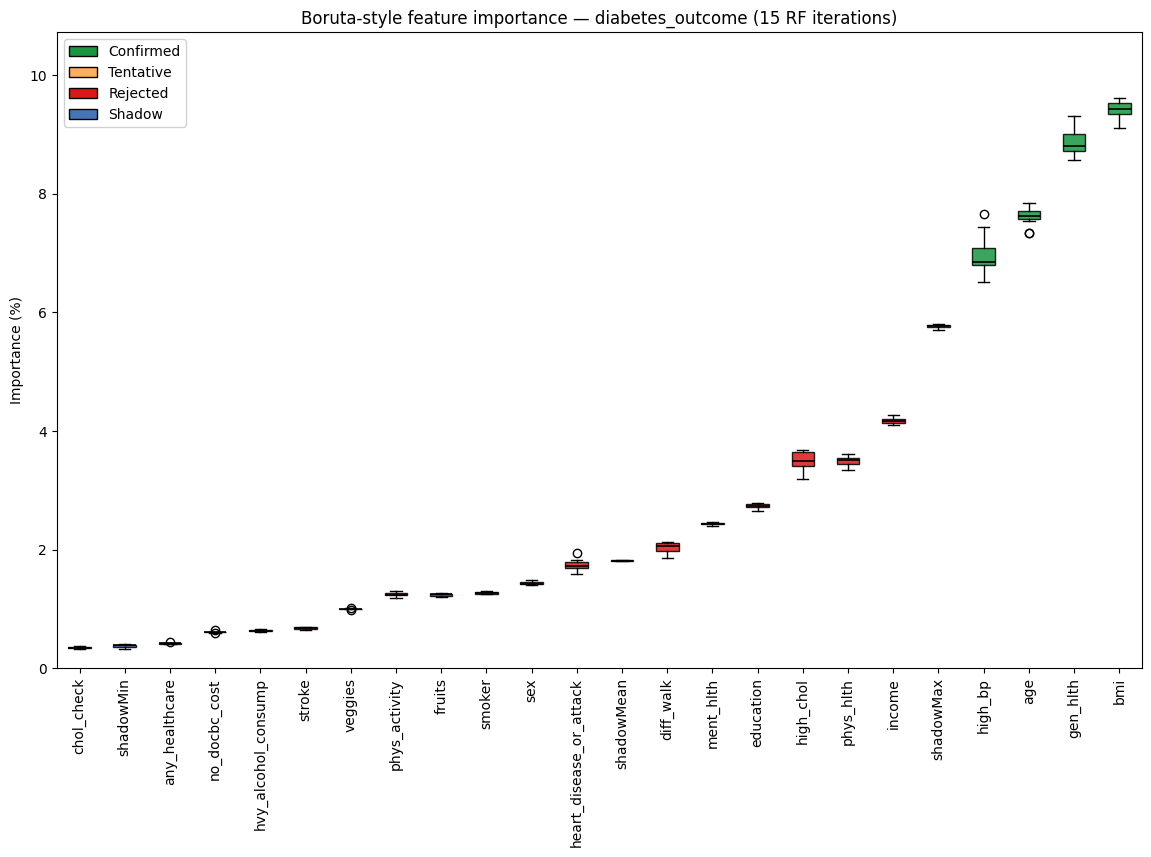

In [51]:
# Cell 14 · Boruta importance plot
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch

if "boruta_importance" not in globals():
    raise RuntimeError("Run Cell 13 (Boruta RF) first.")

BORUTA_COLORS = {
    "confirmed": "#1a9641",
    "rejected": "#d7191c",
    "tentative": "#fdae61",
    "shadow": "#4575b4",
}

shadow_stats = {
    "shadowMin": shadow_min_hist,
    "shadowMean": shadow_mean_hist,
    "shadowMax": shadow_max_hist,
}

plot_items: list[tuple[str, list[float], str]] = []
for feature in feature_names:
    plot_items.append(
        (feature, importance_history[feature], boruta_importance.loc[feature, "decision"])
    )
for shadow_name, shadow_hist in shadow_stats.items():
    plot_items.append((shadow_name, shadow_hist, "shadow"))

plot_items.sort(key=lambda item: np.median(item[1]))
plot_labels = [item[0] for item in plot_items]
plot_data = [[v * 100 for v in item[1]] for item in plot_items]
plot_colors = [BORUTA_COLORS[item[2]] for item in plot_items]

fig, ax = plt.subplots(figsize=(max(14, len(plot_labels) * 0.35), 12))
boxplot = ax.boxplot(
    plot_data,
    tick_labels=plot_labels,
    vert=True,
    patch_artist=True,
    showfliers=True,
    medianprops={"color": "black", "linewidth": 1.2},
)
for patch, color in zip(boxplot["boxes"], plot_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.85)

all_plot_vals = [v for series in plot_data for v in series]
y_min, y_max = min(all_plot_vals), max(all_plot_vals)
y_pad = max((y_max - y_min) * 0.12, 0.05)
ax.set_ylim(max(0.0, y_min - y_pad), y_max + y_pad)

ax.set_ylabel("Importance (%)")
ax.set_title(
    f"Boruta-style feature importance — {BORUTA_TARGET} ({BORUTA_N_ITER} RF iterations)"
)
legend_handles = [
    Patch(facecolor=BORUTA_COLORS["confirmed"], edgecolor="black", label="Confirmed"),
    Patch(facecolor=BORUTA_COLORS["tentative"], edgecolor="black", label="Tentative"),
    Patch(facecolor=BORUTA_COLORS["rejected"], edgecolor="black", label="Rejected"),
    Patch(facecolor=BORUTA_COLORS["shadow"], edgecolor="black", label="Shadow"),
]
ax.legend(handles=legend_handles, loc="upper left", framealpha=0.9)
ax.tick_params(axis="x", rotation=90)
fig.subplots_adjust(bottom=0.35)
plt.show()


**Cell 15 · Binary modeling overview**

Predict **`diabetes_outcome`** from **`df_model_scaled`** with **4-fold cross-validation** (stratified, shuffled, `random_state=42`). Each fold: train on 75%, test on 25%. We show metrics per fold, mean ± std across folds, and **out-of-fold** ROC/confusion plots (every person appears in the test set exactly once).

### Uneven classes (~14% diabetes)

Cells **12–14** (Boruta) rank predictors for interpretation only; **`MODELING_PREDICTOR_COLS`** is unchanged in Cells **16–18**. Cells **19–21** optionally refit **logistic regression** on Boruta-**confirmed** features and compare to the all-feature models (including **AIC**).

In each fold, Cell 16 builds **`class_weight = {0: w_no_diabetes, 1: w_diabetes}`** from that fold’s training counts. **`w_diabetes`** is set so diabetes rows count roughly **6×** more in the loss than non-diabetes rows (matching how much rarer they are). Logistic regression and the random forest read those two numbers at **`fit`** time. Set **`DM_MINORITY_CLASS_WEIGHT_EMPHASIS > 1`** in Cell 16 to increase **`w_diabetes`** further (higher recall on diabetes, usually more false alarms).

### Balanced accuracy (what it means)

**Balanced accuracy** is the average of “how often we get **no diabetes** right” and “how often we get **diabetes** right,” treating both groups equally. Range 0–1; **0.5** is no better than guessing both labels blindly. Unlike overall **accuracy**, it does not look good when the model mostly predicts the common label (no diabetes) and ignores the rare one.

We also report **ROC AUC** (ranking quality), **precision** / **recall** / **F1** for diabetes at threshold 0.5, and a **always predict no diabetes** accuracy baseline.

Random forest uses **`max_samples=50_000`** per tree for runtime on ~250k BRFSS rows.


Full sample: n=253,680, diabetes prevalence = 13.933%
Majority-class baseline (always predict no diabetes): accuracy = 86.067%
Example class_weight fed to the model (full sample, emphasis=1.0): no diabetes (0)=0.5809, diabetes (1)=3.5885 (diabetes mistakes weighted 6.18× more)
Logistic regression fold 1/4: AUC=0.8282, F1=0.4491, recall=0.7856, n_test=63,420
Logistic regression fold 2/4: AUC=0.8260, F1=0.4445, recall=0.7673, n_test=63,420
Logistic regression fold 3/4: AUC=0.8234, F1=0.4441, recall=0.7668, n_test=63,420
Logistic regression fold 4/4: AUC=0.8207, F1=0.4416, recall=0.7616, n_test=63,420

Logistic regression — 4-fold CV summary (mean ± std):


,mean,std
accuracy,0.7321,0.0005
balanced_accuracy,0.7481,0.0037
precision,0.3127,0.0012
recall,0.7703,0.0091
f1,0.4448,0.0027
roc_auc,0.8246,0.0028



=== Logistic regression — out-of-fold evaluation ===
Logistic regression (4-fold OOF) — ROC AUC: 0.8246


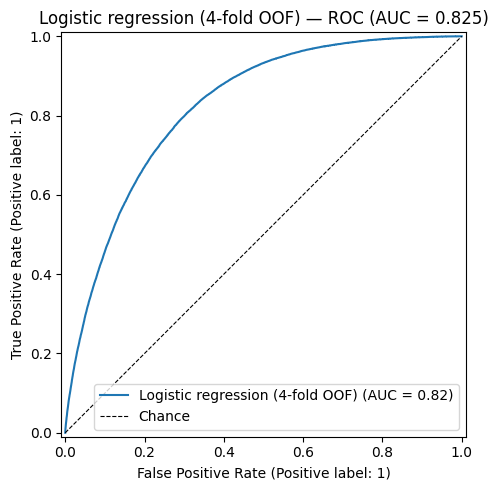

Confusion matrix (rows = true, columns = predicted):
[[158491  59843]
 [  8118  27228]]


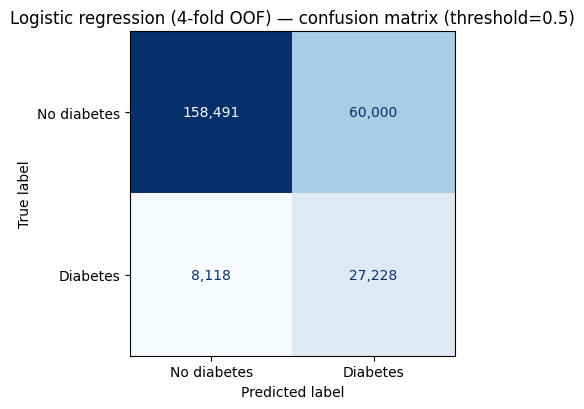

,value
accuracy,0.7321
balanced_accuracy,0.7481
precision,0.3127
recall,0.7703
f1,0.4448
roc_auc,0.8246


              precision    recall  f1-score   support

 No diabetes      0.951     0.726     0.823    218334
    Diabetes      0.313     0.770     0.445     35346

    accuracy                          0.732    253680
   macro avg      0.632     0.748     0.634    253680
weighted avg      0.862     0.732     0.771    253680


Coefficients — full-sample refit, target=diabetes_outcome, predictors=21
Intercept: -4.6334


,feature,coefficient,odds_ratio
2,chol_check,1.2728,3.5707
10,hvy_alcohol_consump,-0.7232,0.4852
0,high_bp,0.7101,2.0341
13,gen_hlth,0.5800,1.7861
1,high_chol,0.5640,1.7577
3,bmi,0.5472,1.7284
17,sex,0.2562,1.2920
6,heart_disease_or_attack,0.2523,1.2869
5,stroke,0.1819,1.1996
18,age,0.1511,1.1631


In [52]:
# Cell 16 · CV setup, class weights & logistic regression (4-fold)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    RocCurveDisplay,
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold

if "df_model_scaled" not in globals():
    raise NameError("Run Cell 10 first.")

DM_MODEL_RANDOM_STATE = 42
DM_CV_FOLDS = 4
DM_MINORITY_CLASS_WEIGHT_EMPHASIS = 1.0
DIABETES_CLASS_NAMES = ["No diabetes", "Diabetes"]

frame = df_model_scaled.copy()
X = frame[MODELING_PREDICTOR_COLS].astype(float)
y = frame[DIABETES_OUTCOME_COL].astype(int)
if X.isna().any().any():
    raise ValueError("Predictors contain NaN.")

overall_prev = float(y.mean())
majority_baseline_acc = float((y == 0).mean())
print(f"Full sample: n={len(y):,}, diabetes prevalence = {overall_prev:.3%}")
print(
    f"Majority-class baseline (always predict no diabetes): "
    f"accuracy = {majority_baseline_acc:.3%}"
)


def dm_class_weight_dict(y_train, emphasis: float = 1.0) -> dict[int, float]:
    """Two fit-time weights {0, 1}; class 1 upweighted by rarity × emphasis."""
    y_arr = np.asarray(y_train, dtype=int)
    n = len(y_arr)
    n0 = int((y_arr == 0).sum())
    n1 = int((y_arr == 1).sum())
    if n0 == 0 or n1 == 0:
        raise ValueError("Both classes required in training fold.")
    return {
        0: n / (2.0 * n0),
        1: (n / (2.0 * n1)) * emphasis,
    }


ref_weights = dm_class_weight_dict(y, DM_MINORITY_CLASS_WEIGHT_EMPHASIS)
print(
    f"Example class_weight fed to the model (full sample, emphasis={DM_MINORITY_CLASS_WEIGHT_EMPHASIS}): "
    f"no diabetes (0)={ref_weights[0]:.4f}, diabetes (1)={ref_weights[1]:.4f} "
    f"(diabetes mistakes weighted {ref_weights[1] / ref_weights[0]:.2f}× more)"
)

dm_skf = StratifiedKFold(
    n_splits=DM_CV_FOLDS,
    shuffle=True,
    random_state=DM_MODEL_RANDOM_STATE,
)


def _dm_fold_metrics(y_true, y_pred, y_prob) -> dict[str, float]:
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_prob),
    }


def _dm_binary_classification_eval(
    y_true,
    y_pred,
    y_prob_positive,
    class_names: list[str],
    model_title: str,
    cm_cmap: str = "Blues",
) -> pd.Series:
    """ROC/AUC, confusion matrix, and metrics (binary)."""
    test_auc = roc_auc_score(y_true, y_prob_positive)
    print(f"{model_title} — ROC AUC: {test_auc:.4f}")

    fig, ax = plt.subplots(figsize=(6, 5))
    RocCurveDisplay.from_predictions(
        y_true,
        y_prob_positive,
        ax=ax,
        name=model_title,
    )
    ax.plot([0, 1], [0, 1], "k--", lw=0.8, label="Chance")
    ax.set_title(f"{model_title} — ROC (AUC = {test_auc:.3f})")
    ax.legend(loc="lower right")
    fig.tight_layout()
    plt.show()

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    print("Confusion matrix (rows = true, columns = predicted):")
    print(cm)

    fig_cm, ax_cm = plt.subplots(figsize=(4.8, 4.2))
    ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names).plot(
        ax=ax_cm,
        cmap=cm_cmap,
        colorbar=False,
    )
    ax_cm.set_title(f"{model_title} — confusion matrix (threshold=0.5)")
    fig_cm.tight_layout()
    plt.show()

    metrics = pd.Series(_dm_fold_metrics(y_true, y_pred, y_prob_positive), name="value")
    display(metrics.to_frame())
    print(classification_report(y_true, y_pred, target_names=class_names, digits=3))
    return metrics


def dm_logistic_aic(
    model: LogisticRegression,
    X_df: pd.DataFrame,
    y_s: pd.Series,
    emphasis: float = 1.0,
) -> float:
    """AIC from class-weighted Bernoulli log-likelihood (full-sample refit)."""
    cw = dm_class_weight_dict(y_s, emphasis)
    y_arr = np.asarray(y_s, dtype=int)
    sw = np.where(y_arr == 1, cw[1], cw[0])
    p1 = np.clip(model.predict_proba(X_df)[:, 1], 1e-15, 1 - 1e-15)
    ll_i = y_arr * np.log(p1) + (1 - y_arr) * np.log(1 - p1)
    log_lik = float((sw * ll_i).sum())
    k = int(model.coef_.size + 1)
    return float(2 * k - 2 * log_lik)


def dm_run_cv(
    estimator,
    X_df: pd.DataFrame,
    y_s: pd.Series,
    cv: StratifiedKFold,
    emphasis: float,
    model_name: str,
) -> tuple[pd.DataFrame, pd.DataFrame, np.ndarray, np.ndarray]:
    oof_prob = np.zeros(len(y_s), dtype=float)
    oof_pred = np.zeros(len(y_s), dtype=int)
    fold_rows: list[dict] = []

    for fold, (train_idx, test_idx) in enumerate(cv.split(X_df, y_s), start=1):
        X_tr, X_te = X_df.iloc[train_idx], X_df.iloc[test_idx]
        y_tr, y_te = y_s.iloc[train_idx], y_s.iloc[test_idx]
        cw = dm_class_weight_dict(y_tr, emphasis)
        est = clone(estimator)
        est.set_params(class_weight=cw)
        est.fit(X_tr, y_tr)
        prob = est.predict_proba(X_te)[:, 1]
        pred = est.predict(X_te)
        oof_prob[test_idx] = prob
        oof_pred[test_idx] = pred
        m = _dm_fold_metrics(y_te, pred, prob)
        m["fold"] = fold
        m["n_train"] = len(y_tr)
        m["n_test"] = len(y_te)
        m["test_prevalence"] = float(y_te.mean())
        m["class_weight_1"] = cw[1]
        fold_rows.append(m)
        print(
            f"{model_name} fold {fold}/{DM_CV_FOLDS}: "
            f"AUC={m['roc_auc']:.4f}, F1={m['f1']:.4f}, "
            f"recall={m['recall']:.4f}, n_test={len(y_te):,}"
        )

    detail = pd.DataFrame(fold_rows).set_index("fold")
    metric_cols = [
        "accuracy",
        "balanced_accuracy",
        "precision",
        "recall",
        "f1",
        "roc_auc",
    ]
    summary = pd.DataFrame(
        {
            "mean": detail[metric_cols].mean(),
            "std": detail[metric_cols].std(ddof=0),
        }
    )
    print(f"\n{model_name} — {DM_CV_FOLDS}-fold CV summary (mean ± std):")
    display(summary.round(4))
    return detail, summary, oof_pred, oof_prob


dm_logistic_base = LogisticRegression(max_iter=5000, solver="lbfgs")
(
    dm_logistic_cv_detail,
    dm_logistic_cv_summary,
    dm_logistic_oof_pred,
    dm_logistic_oof_prob,
) = dm_run_cv(
    dm_logistic_base,
    X,
    y,
    dm_skf,
    DM_MINORITY_CLASS_WEIGHT_EMPHASIS,
    "Logistic regression",
)

print("\n=== Logistic regression — out-of-fold evaluation ===")
dm_logistic_test_metrics = _dm_binary_classification_eval(
    y,
    dm_logistic_oof_pred,
    dm_logistic_oof_prob,
    DIABETES_CLASS_NAMES,
    f"Logistic regression ({DM_CV_FOLDS}-fold OOF)",
    cm_cmap="Blues",
)
dm_logistic_test_metrics.name = "logistic_regression"

dm_logistic_model = LogisticRegression(
    max_iter=5000,
    solver="lbfgs",
    class_weight=dm_class_weight_dict(y, DM_MINORITY_CLASS_WEIGHT_EMPHASIS),
)
dm_logistic_model.fit(X, y)

dm_logistic_coef_table = pd.DataFrame(
    {
        "feature": MODELING_PREDICTOR_COLS,
        "coefficient": dm_logistic_model.coef_.ravel(),
    }
)
dm_logistic_coef_table["odds_ratio"] = np.exp(dm_logistic_coef_table["coefficient"])

print(
    f"\nCoefficients — full-sample refit, target={DIABETES_OUTCOME_COL}, "
    f"predictors={len(MODELING_PREDICTOR_COLS)}"
)
print(f"Intercept: {float(dm_logistic_model.intercept_[0]):.4f}")
display(
    dm_logistic_coef_table.sort_values(
        "coefficient", key=lambda s: s.abs(), ascending=False
    ).head(15)
)


Random forest fold 1/4: AUC=0.8186, F1=0.4535, recall=0.7028, n_test=63,420
Random forest fold 2/4: AUC=0.8168, F1=0.4502, recall=0.6907, n_test=63,420
Random forest fold 3/4: AUC=0.8153, F1=0.4477, recall=0.6809, n_test=63,420
Random forest fold 4/4: AUC=0.8131, F1=0.4478, recall=0.6815, n_test=63,420

Random forest — 4-fold CV summary (mean ± std):


,mean,std
accuracy,0.7652,0.0008
balanced_accuracy,0.7332,0.0033
precision,0.3339,0.0005
recall,0.6890,0.0089
f1,0.4498,0.0023
roc_auc,0.8159,0.0020



=== Random forest — out-of-fold evaluation ===
Random forest (4-fold OOF) — ROC AUC: 0.8159


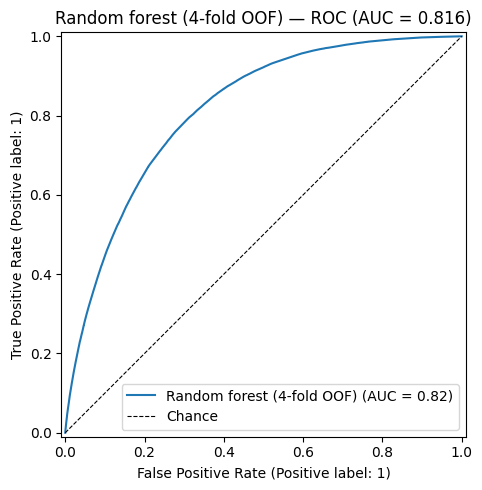

Confusion matrix (rows = true, columns = predicted):
[[169758  48576]
 [ 10994  24352]]


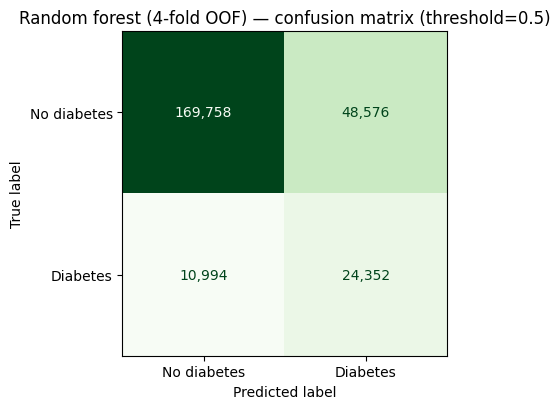

,value
accuracy,0.7652
balanced_accuracy,0.7332
precision,0.3339
recall,0.6890
f1,0.4498
roc_auc,0.8159


              precision    recall  f1-score   support

 No diabetes      0.939     0.778     0.851    218334
    Diabetes      0.334     0.689     0.450     35346

    accuracy                          0.765    253680
   macro avg      0.637     0.733     0.650    253680
weighted avg      0.855     0.765     0.795    253680


Feature importance — full-sample refit, trees=200, max_samples=50,000


,feature,importance
3,bmi,0.1709
18,age,0.1262
13,gen_hlth,0.1055
20,income,0.0840
0,high_bp,0.0764
15,phys_hlth,0.0689
19,education,0.0577
14,ment_hlth,0.0529
1,high_chol,0.0397
4,smoker,0.0288


In [53]:
# Cell 17 · Random forest — 4-fold CV & feature importance
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier

if "X" not in globals() or "y" not in globals() or "dm_run_cv" not in globals():
    raise NameError("Run Cell 16 first.")

DM_RF_MAX_SAMPLES = 50_000

dm_rf_base = RandomForestClassifier(
    n_estimators=200,
    max_samples=DM_RF_MAX_SAMPLES,
    random_state=DM_MODEL_RANDOM_STATE,
    n_jobs=1,
)

(
    dm_rf_cv_detail,
    dm_rf_cv_summary,
    dm_rf_oof_pred,
    dm_rf_oof_prob,
) = dm_run_cv(
    dm_rf_base,
    X,
    y,
    dm_skf,
    DM_MINORITY_CLASS_WEIGHT_EMPHASIS,
    "Random forest",
)

print("\n=== Random forest — out-of-fold evaluation ===")
dm_rf_test_metrics = _dm_binary_classification_eval(
    y,
    dm_rf_oof_pred,
    dm_rf_oof_prob,
    DIABETES_CLASS_NAMES,
    f"Random forest ({DM_CV_FOLDS}-fold OOF)",
    cm_cmap="Greens",
)
dm_rf_test_metrics.name = "random_forest"

dm_rf_model = RandomForestClassifier(
    n_estimators=200,
    max_samples=DM_RF_MAX_SAMPLES,
    random_state=DM_MODEL_RANDOM_STATE,
    class_weight=dm_class_weight_dict(y, DM_MINORITY_CLASS_WEIGHT_EMPHASIS),
    n_jobs=1,
)
dm_rf_model.fit(X, y)

dm_rf_importance = pd.DataFrame(
    {
        "feature": MODELING_PREDICTOR_COLS,
        "importance": dm_rf_model.feature_importances_,
    }
).sort_values("importance", ascending=False)

print(
    f"\nFeature importance — full-sample refit, trees=200, "
    f"max_samples={DM_RF_MAX_SAMPLES:,}"
)
display(dm_rf_importance.head(15))


In [54]:
# Cell 18 · Compare logistic vs random forest (4-fold CV)
import numpy as np
from IPython.display import display

if "dm_logistic_aic" not in globals():
    if "dm_class_weight_dict" not in globals():
        raise NameError("Run Cell 16 first.")

    def dm_logistic_aic(model, X_df, y_s, emphasis=1.0):
        cw = dm_class_weight_dict(y_s, emphasis)
        y_arr = np.asarray(y_s, dtype=int)
        sw = np.where(y_arr == 1, cw[1], cw[0])
        p1 = np.clip(model.predict_proba(X_df)[:, 1], 1e-15, 1 - 1e-15)
        ll_i = y_arr * np.log(p1) + (1 - y_arr) * np.log(1 - p1)
        log_lik = float((sw * ll_i).sum())
        k = int(model.coef_.size + 1)
        return float(2 * k - 2 * log_lik)

if "dm_logistic_cv_summary" not in globals() or "dm_rf_cv_summary" not in globals():
    raise NameError("Run Cells 16 and 17 first.")

dm_model_comparison = pd.DataFrame(
    {
        "logistic_regression": dm_logistic_cv_summary["mean"],
        "random_forest": dm_rf_cv_summary["mean"],
    }
)
dm_model_comparison["delta_rf_minus_logistic"] = (
    dm_model_comparison["random_forest"] - dm_model_comparison["logistic_regression"]
)

if "dm_logistic_model" not in globals():
    raise NameError("Run Cell 16 first (need dm_logistic_model for AIC).")
dm_model_comparison.loc["aic"] = {
    "logistic_regression": dm_logistic_aic(
        dm_logistic_model, X, y, DM_MINORITY_CLASS_WEIGHT_EMPHASIS
    ),
    "random_forest": np.nan,
}

print(
    f"CV comparison — {DM_CV_FOLDS} folds, n={len(y):,}, "
    f"predictors={len(MODELING_PREDICTOR_COLS)}, "
    f"minority emphasis={DM_MINORITY_CLASS_WEIGHT_EMPHASIS}, "
    f"random_state={DM_MODEL_RANDOM_STATE}"
)
display(dm_model_comparison.round(4))
print(
    "AIC row: full-sample logistic refit, class-weighted likelihood "
    "(lower is better). Random forest: AIC not applicable."
)

print("\nPer-fold ROC AUC:")
display(
    pd.DataFrame(
        {
            "logistic_auc": dm_logistic_cv_detail["roc_auc"],
            "rf_auc": dm_rf_cv_detail["roc_auc"],
        }
    ).round(4)
)

auc_log = float(dm_logistic_cv_summary.loc["roc_auc", "mean"])
auc_rf = float(dm_rf_cv_summary.loc["roc_auc", "mean"])
if auc_rf > auc_log:
    winner = "random forest"
elif auc_rf < auc_log:
    winner = "logistic regression"
else:
    winner = "tie"
print(
    f"Higher mean CV ROC AUC: {winner} "
    f"(logistic={auc_log:.4f}, RF={auc_rf:.4f})."
)


CV comparison — 4 folds, n=253,680, predictors=21, minority emphasis=1.0, random_state=42


,logistic_regression,random_forest,delta_rf_minus_logistic
accuracy,0.7321,0.7652,0.0331
balanced_accuracy,0.7481,0.7332,-0.0149
precision,0.3127,0.3339,0.0212
recall,0.7703,0.6890,-0.0814
f1,0.4448,0.4498,0.0050
roc_auc,0.8246,0.8159,-0.0086
aic,259372.1149,NaN,NaN


AIC row: full-sample logistic refit, class-weighted likelihood (lower is better). Random forest: AIC not applicable.

Per-fold ROC AUC:


,logistic_auc,rf_auc
fold,,
1,0.8282,0.8186
2,0.8260,0.8168
3,0.8234,0.8153
4,0.8207,0.8131


Higher mean CV ROC AUC: logistic regression (logistic=0.8246, RF=0.8159).


**Cell 19 · Boruta-confirmed logistic overview**

After Boruta (Cells **13–14**), we refit **logistic regression** using only **confirmed** predictors (`decision == "confirmed"`). Same **4-fold stratified CV**, **class weights**, and **out-of-fold** ROC / confusion-matrix visuals as Cell **16**.

Cell **21** compares this reduced model to the full-feature **logistic** and **random forest** models from Cells **16–18** (mean CV metrics).


Boruta confirmed predictors (p=4): ['bmi', 'gen_hlth', 'age', 'high_bp']
Logistic regression (Boruta confirmed) fold 1/4: AUC=0.8173, F1=0.4393, recall=0.7768, n_test=63,420
Logistic regression (Boruta confirmed) fold 2/4: AUC=0.8125, F1=0.4316, recall=0.7569, n_test=63,420
Logistic regression (Boruta confirmed) fold 3/4: AUC=0.8106, F1=0.4303, recall=0.7544, n_test=63,420
Logistic regression (Boruta confirmed) fold 4/4: AUC=0.8097, F1=0.4304, recall=0.7552, n_test=63,420

Logistic regression (Boruta confirmed) — 4-fold CV summary (mean ± std):


,mean,std
accuracy,0.7223,0.0009
balanced_accuracy,0.7384,0.0044
precision,0.3025,0.0022
recall,0.7609,0.0093
f1,0.4329,0.0037
roc_auc,0.8125,0.0029



=== Logistic regression (Boruta confirmed) — out-of-fold evaluation ===
Logistic regression — Boruta confirmed (4-fold OOF) — ROC AUC: 0.8125


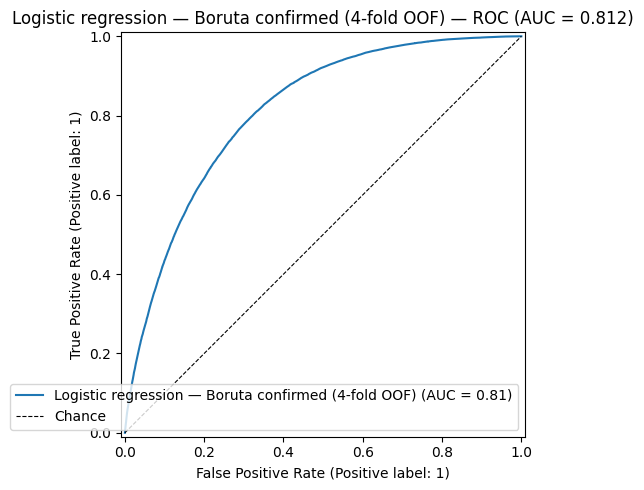

Confusion matrix (rows = true, columns = predicted):
[[156333  62001]
 [  8453  26893]]


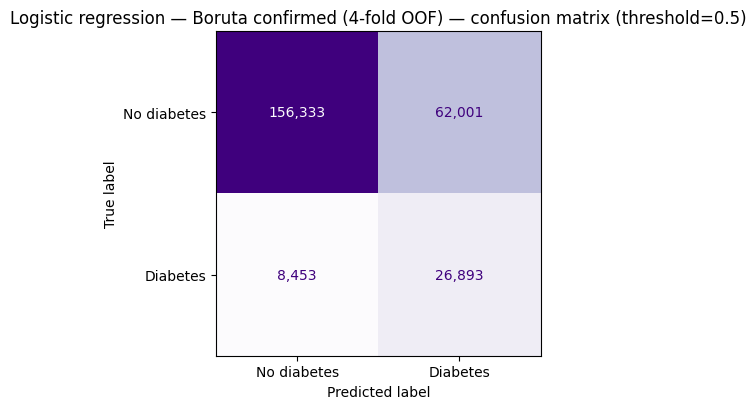

,value
accuracy,0.7223
balanced_accuracy,0.7384
precision,0.3025
recall,0.7608
f1,0.4329
roc_auc,0.8125


              precision    recall  f1-score   support

 No diabetes      0.949     0.716     0.816    218334
    Diabetes      0.303     0.761     0.433     35346

    accuracy                          0.722    253680
   macro avg      0.626     0.738     0.625    253680
weighted avg      0.859     0.722     0.763    253680


Coefficients — full-sample refit, target=diabetes_outcome, predictors=4 (Boruta confirmed)
Intercept: -4.1022


,feature,coefficient,odds_ratio
3,high_bp,0.8649,2.3747
1,gen_hlth,0.6558,1.9267
0,bmi,0.5717,1.7712
2,age,0.1832,1.2010


In [55]:
# Cell 20 · Logistic regression — Boruta confirmed features only
from IPython.display import display
from sklearn.linear_model import LogisticRegression

if "boruta_importance" not in globals():
    raise NameError("Run Cells 13–14 (Boruta) first.")
if "X" not in globals() or "y" not in globals() or "dm_run_cv" not in globals():
    raise NameError("Run Cell 16 first.")

BORUTA_CONFIRMED_PREDICTOR_COLS = (
    boruta_importance.loc[boruta_importance["decision"] == "confirmed"]
    .sort_values(["hit_rate", "mean_importance"], ascending=False)
    .index.tolist()
)
BORUTA_CONFIRMED_PREDICTOR_COLS = [
    c for c in BORUTA_CONFIRMED_PREDICTOR_COLS if c in MODELING_PREDICTOR_COLS
]
if not BORUTA_CONFIRMED_PREDICTOR_COLS:
    raise ValueError("No Boruta-confirmed features in MODELING_PREDICTOR_COLS.")

print(
    f"Boruta confirmed predictors (p={len(BORUTA_CONFIRMED_PREDICTOR_COLS)}): "
    f"{BORUTA_CONFIRMED_PREDICTOR_COLS}"
)

X_boruta_confirmed = X[BORUTA_CONFIRMED_PREDICTOR_COLS].astype(float)

dm_logistic_boruta_base = LogisticRegression(max_iter=5000, solver="lbfgs")
(
    dm_logistic_boruta_cv_detail,
    dm_logistic_boruta_cv_summary,
    dm_logistic_boruta_oof_pred,
    dm_logistic_boruta_oof_prob,
) = dm_run_cv(
    dm_logistic_boruta_base,
    X_boruta_confirmed,
    y,
    dm_skf,
    DM_MINORITY_CLASS_WEIGHT_EMPHASIS,
    "Logistic regression (Boruta confirmed)",
)

print("\n=== Logistic regression (Boruta confirmed) — out-of-fold evaluation ===")
dm_logistic_boruta_test_metrics = _dm_binary_classification_eval(
    y,
    dm_logistic_boruta_oof_pred,
    dm_logistic_boruta_oof_prob,
    DIABETES_CLASS_NAMES,
    f"Logistic regression — Boruta confirmed ({DM_CV_FOLDS}-fold OOF)",
    cm_cmap="Purples",
)
dm_logistic_boruta_test_metrics.name = "logistic_boruta_confirmed"

dm_logistic_boruta_model = LogisticRegression(
    max_iter=5000,
    solver="lbfgs",
    class_weight=dm_class_weight_dict(y, DM_MINORITY_CLASS_WEIGHT_EMPHASIS),
)
dm_logistic_boruta_model.fit(X_boruta_confirmed, y)

dm_logistic_boruta_coef_table = pd.DataFrame(
    {
        "feature": BORUTA_CONFIRMED_PREDICTOR_COLS,
        "coefficient": dm_logistic_boruta_model.coef_.ravel(),
    }
)
dm_logistic_boruta_coef_table["odds_ratio"] = np.exp(
    dm_logistic_boruta_coef_table["coefficient"]
)

print(
    f"\nCoefficients — full-sample refit, target={DIABETES_OUTCOME_COL}, "
    f"predictors={len(BORUTA_CONFIRMED_PREDICTOR_COLS)} (Boruta confirmed)"
)
print(f"Intercept: {float(dm_logistic_boruta_model.intercept_[0]):.4f}")
display(
    dm_logistic_boruta_coef_table.sort_values(
        "coefficient", key=lambda s: s.abs(), ascending=False
    )
)


In [56]:
# Cell 21 · Compare all-feature vs Boruta-confirmed logistic vs RF
import numpy as np
from IPython.display import display

if "dm_logistic_aic" not in globals():
    if "dm_class_weight_dict" not in globals():
        raise NameError("Run Cell 16 first.")

    def dm_logistic_aic(model, X_df, y_s, emphasis=1.0):
        cw = dm_class_weight_dict(y_s, emphasis)
        y_arr = np.asarray(y_s, dtype=int)
        sw = np.where(y_arr == 1, cw[1], cw[0])
        p1 = np.clip(model.predict_proba(X_df)[:, 1], 1e-15, 1 - 1e-15)
        ll_i = y_arr * np.log(p1) + (1 - y_arr) * np.log(1 - p1)
        log_lik = float((sw * ll_i).sum())
        k = int(model.coef_.size + 1)
        return float(2 * k - 2 * log_lik)

required = (
    "dm_logistic_cv_summary",
    "dm_rf_cv_summary",
    "dm_logistic_boruta_cv_summary",
    "BORUTA_CONFIRMED_PREDICTOR_COLS",
)
missing = [name for name in required if name not in globals()]
if missing:
    raise NameError(f"Run Cells 16, 17, and 20 first. Missing: {missing}")

metric_index = dm_logistic_cv_summary.index

dm_three_model_comparison = pd.DataFrame(
    {
        "logistic_all_features": dm_logistic_cv_summary["mean"],
        "random_forest_all_features": dm_rf_cv_summary["mean"],
        "logistic_boruta_confirmed": dm_logistic_boruta_cv_summary["mean"],
    },
    index=metric_index,
)
dm_three_model_comparison["delta_boruta_logistic_minus_all"] = (
    dm_three_model_comparison["logistic_boruta_confirmed"]
    - dm_three_model_comparison["logistic_all_features"]
)
dm_three_model_comparison["delta_rf_minus_all_logistic"] = (
    dm_three_model_comparison["random_forest_all_features"]
    - dm_three_model_comparison["logistic_all_features"]
)

if "dm_logistic_model" not in globals() or "dm_logistic_boruta_model" not in globals():
    raise NameError("Run Cells 16 and 20 first (full-sample models for AIC).")
dm_three_model_comparison.loc["aic"] = {
    "logistic_all_features": dm_logistic_aic(
        dm_logistic_model, X, y, DM_MINORITY_CLASS_WEIGHT_EMPHASIS
    ),
    "random_forest_all_features": np.nan,
    "logistic_boruta_confirmed": dm_logistic_aic(
        dm_logistic_boruta_model,
        X_boruta_confirmed,
        y,
        DM_MINORITY_CLASS_WEIGHT_EMPHASIS,
    ),
}

print(
    f"CV comparison — {DM_CV_FOLDS} folds, n={len(y):,}, "
    f"all-features p={len(MODELING_PREDICTOR_COLS)}, "
    f"Boruta confirmed p={len(BORUTA_CONFIRMED_PREDICTOR_COLS)}, "
    f"minority emphasis={DM_MINORITY_CLASS_WEIGHT_EMPHASIS}, "
    f"random_state={DM_MODEL_RANDOM_STATE}"
)
display(dm_three_model_comparison.round(4))
print(
    "AIC row: full-sample logistic refits, class-weighted likelihood "
    "(lower is better). Random forest: AIC not applicable."
)

print("\nPer-fold ROC AUC:")
display(
    pd.DataFrame(
        {
            "logistic_all": dm_logistic_cv_detail["roc_auc"],
            "random_forest_all": dm_rf_cv_detail["roc_auc"],
            "logistic_boruta_confirmed": dm_logistic_boruta_cv_detail["roc_auc"],
        }
    ).round(4)
)

auc_all = float(dm_logistic_cv_summary.loc["roc_auc", "mean"])
auc_rf = float(dm_rf_cv_summary.loc["roc_auc", "mean"])
auc_boruta = float(dm_logistic_boruta_cv_summary.loc["roc_auc", "mean"])
best = max(
    [
        ("logistic (all features)", auc_all),
        ("random forest (all features)", auc_rf),
        ("logistic (Boruta confirmed)", auc_boruta),
    ],
    key=lambda item: item[1],
)
print(
    f"Highest mean CV ROC AUC: {best[0]} ({best[1]:.4f}). "
    f"(all logistic={auc_all:.4f}, RF={auc_rf:.4f}, Boruta logistic={auc_boruta:.4f})"
)


CV comparison — 4 folds, n=253,680, all-features p=21, Boruta confirmed p=4, minority emphasis=1.0, random_state=42


,logistic_all_features,random_forest_all_features,logistic_boruta_confirmed,delta_boruta_logistic_minus_all,delta_rf_minus_all_logistic
accuracy,0.7321,0.7652,0.7223,-0.0098,0.0331
balanced_accuracy,0.7481,0.7332,0.7384,-0.0097,-0.0149
precision,0.3127,0.3339,0.3025,-0.0102,0.0212
recall,0.7703,0.6890,0.7609,-0.0095,-0.0814
f1,0.4448,0.4498,0.4329,-0.0119,0.0050
roc_auc,0.8246,0.8159,0.8125,-0.0121,-0.0086
aic,259372.1149,NaN,266969.5246,NaN,NaN


AIC row: full-sample logistic refits, class-weighted likelihood (lower is better). Random forest: AIC not applicable.

Per-fold ROC AUC:


,logistic_all,random_forest_all,logistic_boruta_confirmed
fold,,,
1,0.8282,0.8186,0.8173
2,0.8260,0.8168,0.8125
3,0.8234,0.8153,0.8106
4,0.8207,0.8131,0.8097


Highest mean CV ROC AUC: logistic (all features) (0.8246). (all logistic=0.8246, RF=0.8159, Boruta logistic=0.8125)
